In [1]:
import pandas as pd

df = pd.read_csv("iris.csv")

df.head()


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (150, 5)

Column Names:
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [4]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [5]:
df["species"].value_counts()


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

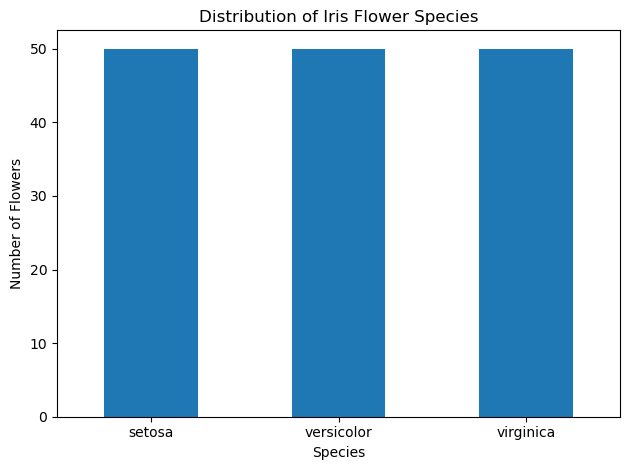

In [6]:
import matplotlib.pyplot as plt

df["species"].value_counts().plot(kind="bar")

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

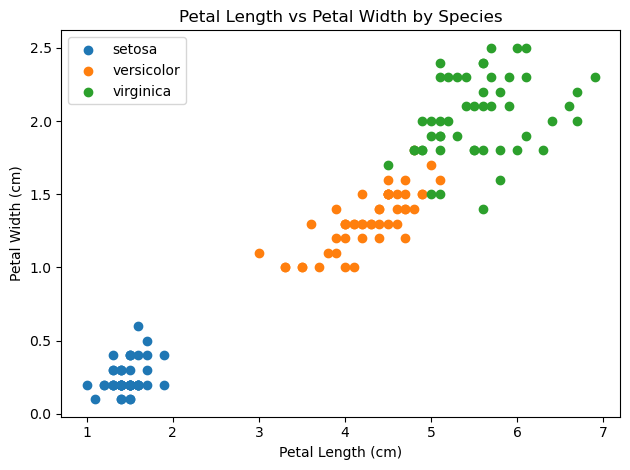

In [7]:
import matplotlib.pyplot as plt

for species in df["species"].unique():
    subset = df[df["species"] == species]
    plt.scatter(
        subset["petal_length"],
        subset["petal_width"],
        label=species
    )

plt.title("Petal Length vs Petal Width by Species")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
X = df.drop("species", axis=1)

y = df["species"]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

Features (X):
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Target (y):
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training records:", len(y_train))
print("Testing records:", len(y_test))

Training features: (120, 4)
Testing features: (30, 4)
Training records: 120
Testing records: 30


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nFirst five rows of scaled training data:")
print(X_train_scaled[:5])

Training data shape: (120, 4)
Testing data shape: (30, 4)

First five rows of scaled training data:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


In [11]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Logistic Regression Results
---------------------------
Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



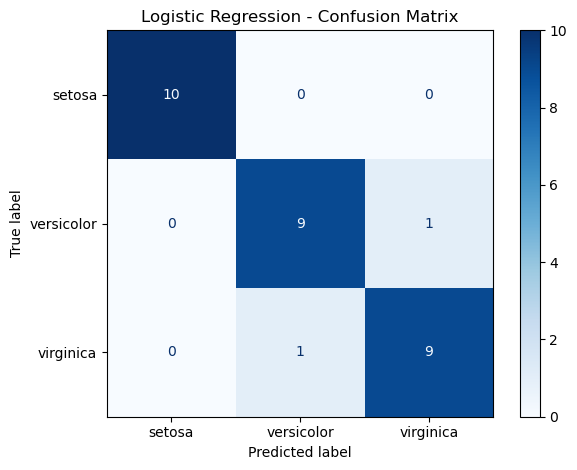

In [12]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict flower species
y_pred_lr = lr_model.predict(X_test_scaled)

# Calculate accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy: {accuracy_lr:.4f}")

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Plot confusion matrix
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=lr_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=lr_model.classes_
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [13]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [14]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate Decision Tree accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Results")
print("---------------------")
print(f"Accuracy: {accuracy_dt:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Results
---------------------
Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [15]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy_lr, accuracy_dt]
})

model_comparison["Accuracy (%)"] = model_comparison["Accuracy"] * 100

print(model_comparison)

                 Model  Accuracy  Accuracy (%)
0  Logistic Regression  0.933333     93.333333
1        Decision Tree  0.933333     93.333333


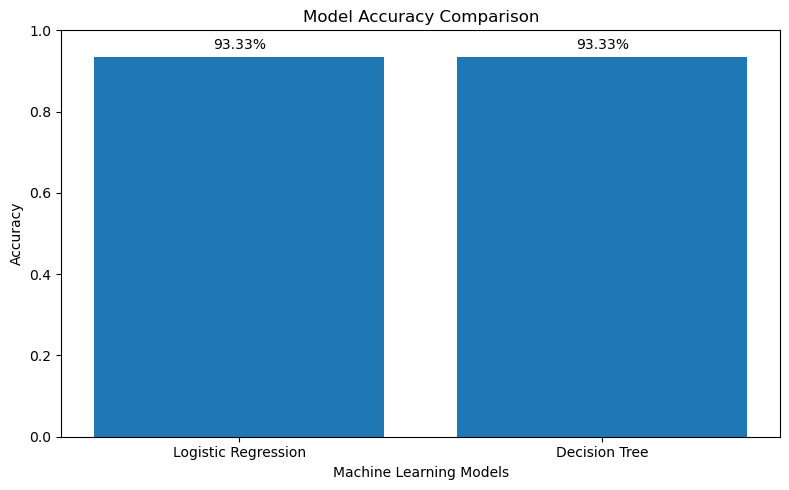

In [16]:
import matplotlib.pyplot as plt

models = ["Logistic Regression", "Decision Tree"]
accuracies = [accuracy_lr, accuracy_dt]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.2%}",
        ha="center"
    )

plt.tight_layout()
plt.show()

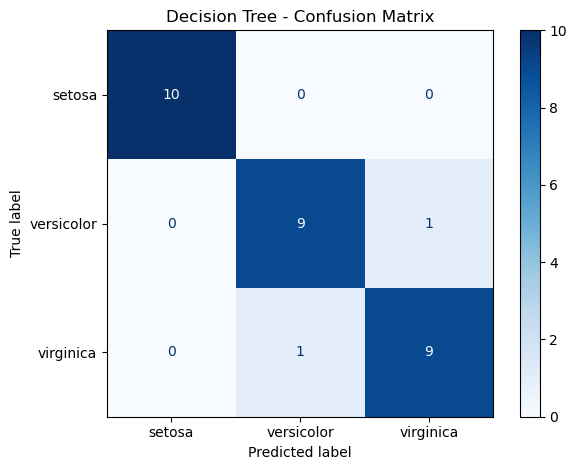

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    labels=dt_model.classes_,
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

        Feature  Importance
2  petal_length    0.558568
3   petal_width    0.406015
1   sepal_width    0.029167
0  sepal_length    0.006250


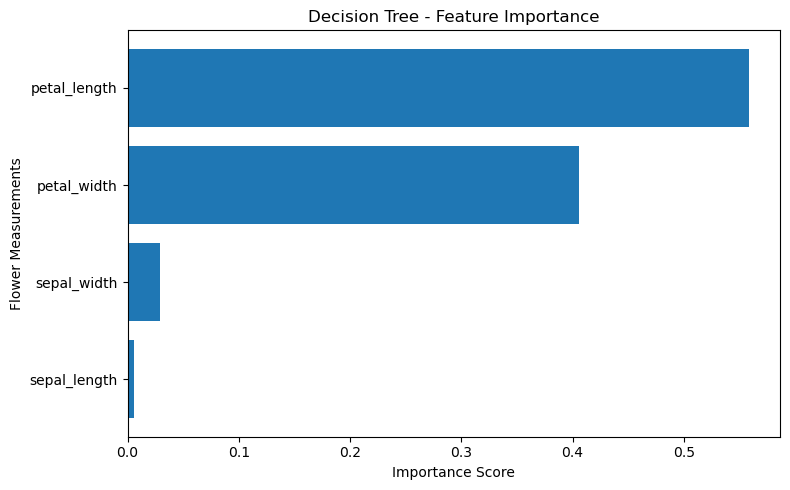

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print(feature_importance)

plt.figure(figsize=(8, 5))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Decision Tree - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Flower Measurements")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [19]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy_lr, accuracy_dt]
})

results["Accuracy (%)"] = results["Accuracy"] * 100

print(results)

                 Model  Accuracy  Accuracy (%)
0  Logistic Regression  0.933333     93.333333
1        Decision Tree  0.933333     93.333333


## Conclusion

The Iris Flower Classification project was completed using the Iris dataset, which contains 150 samples belonging to three species: Setosa, Versicolor, and Virginica.

The dataset was explored and visualized, and the data was divided into training and testing sets. StandardScaler was used to scale the features for Logistic Regression.

Two machine learning algorithms were implemented: Logistic Regression and Decision Tree. Both models achieved an accuracy of 93.33% on the test dataset, correctly classifying 28 out of 30 samples.

The classification report and confusion matrices were used to evaluate model performance. The Decision Tree feature importance analysis helped identify which flower measurements contributed most to its predictions.

Overall, both models performed well on this dataset. Further evaluation with different train-test splits and cross-validation could help assess how consistently the models perform on unseen data.